<a href="https://colab.research.google.com/github/farah-alshiha/understanding-curricula/blob/main/hacker_experiments/curriculum_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!git clone https://github.com/google-research/understanding-curricula.git
!ls understanding-curricula


Cloning into 'understanding-curricula'...
remote: Enumerating objects: 56, done.
remote: Counting objects: 100% (56/56), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 56 (delta 11), reused 45 (delta 6), pack-reused 0 (from 0)
Receiving objects: 100% (56/56), 64.61 KiB | 8.08 MiB/s, done.
Resolving deltas: 100% (11/11), done.
CONTRIBUTING.md  loss-based-cscore.py  orders		 third_party
learnT_order.py  main_wo_test.py       README.md	 utils
LICENSE		 main_w_test.py        requirements.txt


---

In [2]:

from pathlib import Path
from torchvision.datasets import CIFAR10
import numpy as np
import urllib.request

DATA_DIR = Path("/content/cifar_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

train_raw = CIFAR10(root=str(DATA_DIR), train=True, download=True)
test_raw = CIFAR10(root=str(DATA_DIR), train=False, download=True)

url = (
    "https://pluskid.github.io/structural-regularity/cscores/"
    "cifar10-cscores-orig-order.npz"
)
score_file = DATA_DIR / "cifar10-cscores-orig-order.npz"

if not score_file.exists():
    urllib.request.urlretrieve(url, score_file)

scores = np.load(score_file)["scores"].reshape(-1)

assert len(scores) == len(train_raw) == 50000

# The authors sort c-scores in descending order.
# Stable sort makes ties deterministic.
difficulty_order = np.argsort(-scores, kind="stable")

print("Training examples:", len(train_raw))
print("Test examples:", len(test_raw))
print("Difficulty scores:", scores.shape)
print("First 10 ranked indices:", difficulty_order[:10])


100%|██████████| 170M/170M [28:45<00:00, 98.8kB/s]


Training examples: 50000
Test examples: 10000
Difficulty scores: (50000,)
First 10 ranked indices: [  772 35878 25506   942 16938 24680 46131 42649 31502 41786]


---

###1. Preparing datasets and model

In [4]:

import torch
import torchvision
import random
import copy
import pandas as pd
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, models

SEED = 111
BATCH_SIZE = 128
EPOCHS = 20
NUM_WORKERS = 2
DEVICE = "cuda"

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

train_dataset = CIFAR10(
    root=str(DATA_DIR), train=True,
    download=False, transform=train_transform
)

eval_train_dataset = CIFAR10(
    root=str(DATA_DIR), train=True,
    download=False, transform=eval_transform
)

test_dataset = CIFAR10(
    root=str(DATA_DIR), train=False,
    download=False, transform=eval_transform
)

# Class-balanced validation: 500 examples per class.
rng = np.random.default_rng(SEED)
targets = np.asarray(train_raw.targets)

val_indices = []
for c in range(10):
    candidates = np.where(targets == c)[0]
    val_indices.extend(rng.choice(candidates, 500, replace=False))

val_indices = np.array(sorted(val_indices))
train_mask = np.ones(len(train_raw), dtype=bool)
train_mask[val_indices] = False

# Preserve difficulty ranking after removing validation examples.
ranked_train = difficulty_order[train_mask[difficulty_order]]
N = len(ranked_train)

val_loader = DataLoader(
    Subset(eval_train_dataset, val_indices.tolist()),
    batch_size=256, shuffle=False, num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256, shuffle=False, num_workers=NUM_WORKERS
)

def make_model():
    model = models.resnet18(weights=None)
    # CIFAR-friendly stem
    model.conv1 = nn.Conv2d(
        3, 64, kernel_size=3, stride=1, padding=1, bias=False
    )
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model.to(DEVICE)

print("Training:", N)
print("Validation:", len(val_indices))
print("Test:", len(test_dataset))


Training: 45000
Validation: 5000
Test: 10000


###2. Defining curriculum pacing

In [5]:
import math

def active_fraction(progress, pacing="linear", a=0.2, b=0.8):
    """
    progress: fraction of optimizer steps completed, in [0,1]
    a: initial fraction of training data
    b: fraction of training budget over which data is introduced
    """
    t = min(1.0, progress / b)

    if pacing == "linear":
        return a + (1 - a) * t

    if pacing == "quadratic":
        return a + (1 - a) * (t ** 2)

    raise ValueError(f"Unknown pacing: {pacing}")

def get_active_indices(ordering, step, total_steps, pacing):
    if ordering == "standard":
        return ranked_train

    if ordering == "random":
        ordered = random_ranked_train
    else:
        ordered = ranked_train

    fraction = active_fraction(
        step / total_steps, pacing=pacing
    )
    count = min(N, max(256, math.ceil(fraction * N)))

    return ordered[:count]

# Fixed random ordering, shared across the entire run.
random_ranked_train = np.random.default_rng(SEED).permutation(
    ranked_train
)

TOTAL_STEPS = math.ceil(N / BATCH_SIZE) * EPOCHS

for step in [0, TOTAL_STEPS // 4, TOTAL_STEPS // 2, TOTAL_STEPS]:
    frac = active_fraction(step / TOTAL_STEPS)
    print(f"Step {step}: {frac:.1%} available")


Step 0: 20.0% available
Step 1760: 45.0% available
Step 3520: 70.0% available
Step 7040: 100.0% available


###3. Training and evaluation

In [6]:
import torch.nn.functional as F

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    correct, total, total_loss = 0, 0, 0.0

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = model(images)
        loss = F.cross_entropy(logits, labels, reduction="sum")

        total_loss += loss.item()
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return {
        "accuracy": 100.0 * correct / total,
        "loss": total_loss / total
    }

def run_experiment(name, ordering, pacing="linear"):
    seed_everything(SEED)

    model = make_model()
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=0.1,
        momentum=0.9,
        weight_decay=5e-4
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=TOTAL_STEPS
    )

    scaler = torch.amp.GradScaler("cuda")
    records = []
    step = 0

    while step < TOTAL_STEPS:
        indices = get_active_indices(
            ordering, step, TOTAL_STEPS, pacing
        )

        loader = DataLoader(
            Subset(train_dataset, indices.tolist()),
            batch_size=BATCH_SIZE,
            shuffle=True,
            num_workers=NUM_WORKERS,
            pin_memory=True
        )

        model.train()
        loss_sum = 0.0
        examples_seen = 0

        for images, labels in loader:
            if step >= TOTAL_STEPS:
                break

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(images)
                loss = F.cross_entropy(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

            loss_sum += loss.item() * labels.size(0)
            examples_seen += labels.size(0)
            step += 1

        # Evaluate at comparable optimizer-step checkpoints.
        if step >= TOTAL_STEPS or step % max(1, TOTAL_STEPS // 10) < len(loader):
            val = evaluate(model, val_loader)
            records.append({
                "experiment": name,
                "step": step,
                "val_accuracy": val["accuracy"],
                "val_loss": val["loss"],
                "train_loss": loss_sum / max(1, examples_seen),
                "active_samples": len(indices)
            })

            print(
                f"{name:20s} | step {step:5d}/{TOTAL_STEPS} "
                f"| active {len(indices):5d} "
                f"| val acc {val['accuracy']:.2f}%"
            )

    final_val = evaluate(model, val_loader)
    final_test = evaluate(model, test_loader)

    return model, pd.DataFrame(records), {
        "experiment": name,
        "final_val_accuracy": final_val["accuracy"],
        "final_test_accuracy": final_test["accuracy"]
    }


###4. Running all four experiments

In [7]:
EXPERIMENTS = [
    ("Standard", "standard", "linear"),
    ("Curriculum", "curr", "linear"),
    ("Random curriculum", "random", "linear"),
    ("Quadratic curriculum", "curr", "quadratic"),
]

all_histories = []
summaries = []

for name, ordering, pacing in EXPERIMENTS:
    print(f"\n{'='*55}\nRunning: {name}\n{'='*55}")

    model, history, summary = run_experiment(
        name, ordering, pacing
    )

    all_histories.append(history)
    summaries.append(summary)

    torch.save(
        model.state_dict(),
        f"/content/{name.replace(' ', '_')}.pth"
    )

    del model
    torch.cuda.empty_cache()

results = pd.DataFrame(summaries)
history = pd.concat(all_histories, ignore_index=True)

results.to_csv("/content/results.csv", index=False)
history.to_csv("/content/history.csv", index=False)

display(results)



Running: Standard
Standard             | step   704/7040 | active 45000 | val acc 59.64%
Standard             | step  1408/7040 | active 45000 | val acc 69.32%
Standard             | step  2112/7040 | active 45000 | val acc 80.78%
Standard             | step  2816/7040 | active 45000 | val acc 80.14%
Standard             | step  3520/7040 | active 45000 | val acc 83.92%
Standard             | step  4224/7040 | active 45000 | val acc 86.04%
Standard             | step  4928/7040 | active 45000 | val acc 88.64%
Standard             | step  5632/7040 | active 45000 | val acc 89.84%
Standard             | step  6336/7040 | active 45000 | val acc 89.84%
Standard             | step  7040/7040 | active 45000 | val acc 90.16%

Running: Curriculum
Curriculum           | step   781/7040 | active 13322 | val acc 55.64%
Curriculum           | step  1527/7040 | active 17866 | val acc 65.98%
Curriculum           | step  2160/7040 | active 21721 | val acc 68.26%
Curriculum           | step  2931/704

,experiment,final_val_accuracy,final_test_accuracy
0,Standard,90.16,89.54
1,Curriculum,89.42,89.12
2,Random curriculum,87.42,86.77
3,Quadratic curriculum,88.38,87.90


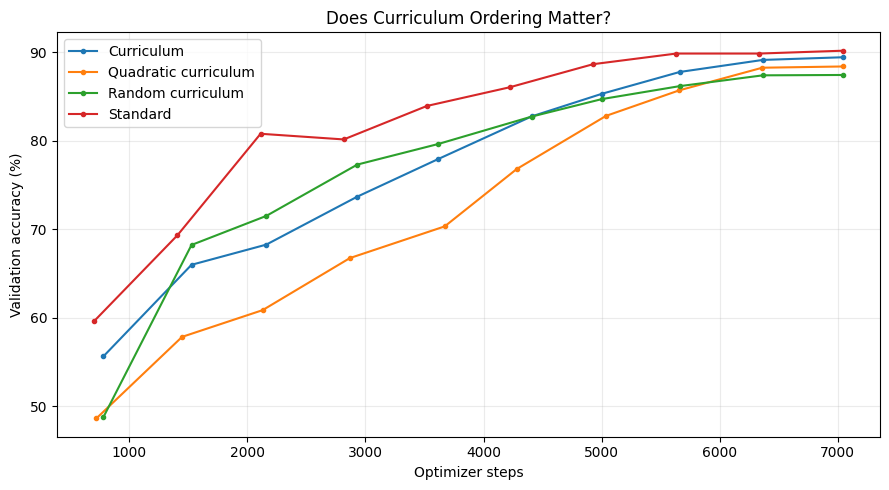

In [8]:
plt.figure(figsize=(9, 5))

for name, group in history.groupby("experiment"):
    group = group.sort_values("step")
    plt.plot(
        group["step"],
        group["val_accuracy"],
        marker="o",
        markersize=3,
        label=name
    )

plt.xlabel("Optimizer steps")
plt.ylabel("Validation accuracy (%)")
plt.title("Does Curriculum Ordering Matter?")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("/content/curriculum_accuracy.png", dpi=200)
plt.show()


---

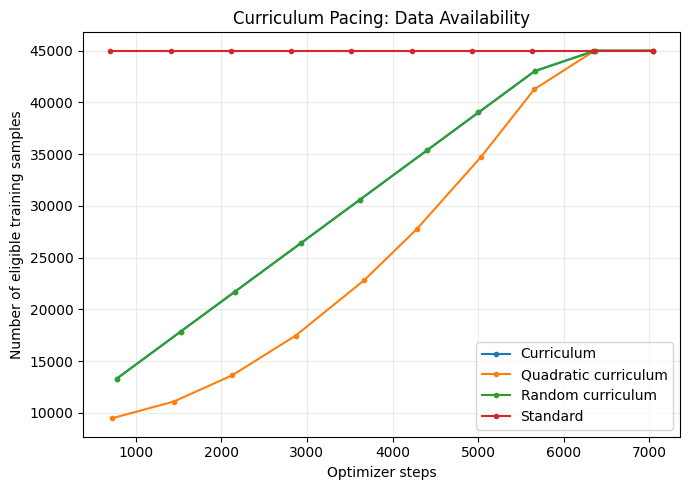

In [11]:
plt.figure(figsize=(7, 5))

for name, group in history.groupby("experiment"):
    group = group.sort_values("step")
    plt.plot(
        group["step"],
        group["active_samples"],
        marker="o",
        markersize=3,
        label=name
    )

plt.xlabel("Optimizer steps")
plt.ylabel("Number of eligible training samples")
plt.title("Curriculum Pacing: Data Availability")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("/content/curriculum_pacing.png", dpi=200)
plt.show()
